In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch import optim
from torch.utils.data import DataLoader, random_split, Subset
from tqdm import tqdm
import matplotlib.pyplot as plt
from pathlib import Path

from autoencoder import autoenc, FizeauDataset
from astropy.io import fits


In [2]:
training_frac = 0.8
N = 100
n_training = int(N*training_frac)
learning_rate = 0.01
batch_size = 20
training_epochs = 20

In [3]:
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
data = Path(r"simulated_images_varied_OPD")
data = sorted(data.glob("*.fits"))

dataset = FizeauDataset(data)

idxs = np.arange(0, N)
np.random.shuffle(idxs)

train_idxs = idxs[:n_training]
test_idxs = idxs[n_training:]

train_dataset = Subset(dataset, train_idxs)
test_dataset = Subset(dataset, test_idxs)

train_loader = DataLoader(train_dataset, batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)


8
torch.Size([512, 2, 2]) torch.Size([1, 60, 60])
9.727933e+07


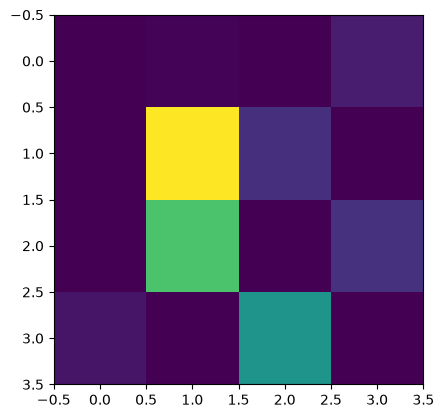

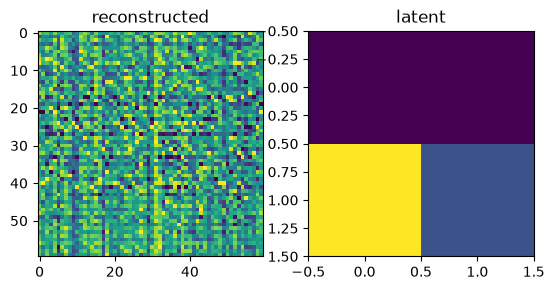

In [5]:
model = autoenc(1)
loss = nn.L1Loss()
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)

lol = train_loader.dataset[0][0]
latent, denoised, layer_reps = model(lol)

print(len(layer_reps))
plt.imshow(layer_reps[4][0].detach().numpy())
print(latent.shape, denoised.shape)

fig, ax = plt.subplots(1, 2)
ax[0].imshow(denoised.detach().numpy()[0, :, :])
ax[1].imshow(latent.detach().numpy()[0, :, :])
ax[0].set_title("reconstructed")
ax[1].set_title("latent")

loss_ = loss(lol, denoised)
print(loss_.detach().numpy())


In [6]:
loss_per_epoch = []

for epoch in range(training_epochs):
    print(f"Epoch [{epoch + 1}/{training_epochs}]")
    for batch_index, (data, _) in enumerate(tqdm(iter(train_loader))):
        # Move data and targets to the device (GPU/CPU)
        data = data.to(device)

        # Forward pass: compute the model output
        latent, reconstructed, _ = model(data)
        loss_ = loss(reconstructed, data)
        loss_per_epoch.append(loss_.detach().numpy())
        
        # Backward pass: compute the gradients
        optimizer.zero_grad()
        loss_.backward()

        # Optimization step: update the model parameters
        optimizer.step()

Epoch [1/20]


100%|██████████| 4/4 [00:00<00:00,  4.37it/s]


Epoch [2/20]


100%|██████████| 4/4 [00:00<00:00,  4.60it/s]


Epoch [3/20]


100%|██████████| 4/4 [00:00<00:00,  5.12it/s]


... (30 outputs left out)

Epoch [19/20]


100%|██████████| 4/4 [00:00<00:00,  6.67it/s]


Epoch [20/20]


100%|██████████| 4/4 [00:00<00:00,  6.25it/s]


[array(9.723411e+07, dtype=float32), array(9.723633e+07, dtype=float32), array(9.722585e+07, dtype=float32), array(9.723152e+07, dtype=float32), array(9.723285e+07, dtype=float32), array(9.72344e+07, dtype=float32), array(9.722601e+07, dtype=float32), array(9.7234536e+07, dtype=float32), array(9.722862e+07, dtype=float32), array(9.723324e+07, dtype=float32), array(9.723141e+07, dtype=float32), array(9.723453e+07, dtype=float32), array(9.7232376e+07, dtype=float32), array(9.723243e+07, dtype=float32), array(9.722612e+07, dtype=float32), array(9.723687e+07, dtype=float32), array(9.724508e+07, dtype=float32), array(9.7226136e+07, dtype=float32), array(9.723231e+07, dtype=float32), array(9.722426e+07, dtype=float32), array(9.721635e+07, dtype=float32), array(9.722512e+07, dtype=float32), array(9.724364e+07, dtype=float32), array(9.724269e+07, dtype=float32), array(9.721992e+07, dtype=float32), array(9.723382e+07, dtype=float32), array(9.723591e+07, dtype=float32), array(9.723817e+07, dtype

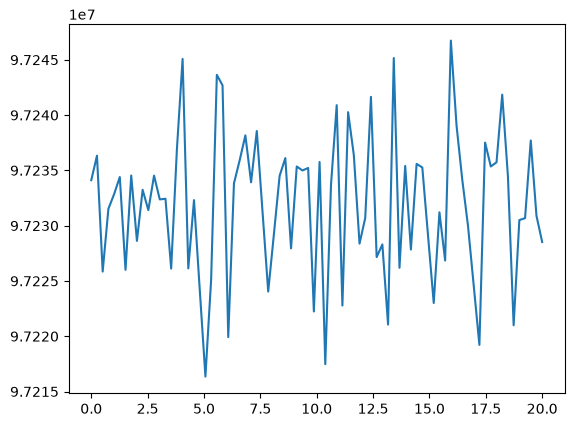

In [7]:
print(loss_per_epoch)
epochs = np.linspace(0, training_epochs, num=len(loss_per_epoch))
plt.plot(epochs, loss_per_epoch)